# Curva de Bragg — PHITS | 10 MeV

Lectura de la salida **[T-Deposit]** (`axis = z`, `output = dose`, `unit = 0`). Se utiliza el centro de cada intervalo de la malla y se identifica el bin con la dosis máxima.

El eje horizontal representa la coordenada **z** del tally; corresponde a profundidad solo si `z = 0` coincide con la entrada al material.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

archivo = Path("../out/pico_bragg10MeV.out")
if not archivo.exists():
    archivo = Path("pico_bragg10MeV.out")

if not archivo.exists():
    raise FileNotFoundError("Colocá pico_bragg10MeV.out en out/ o junto al notebook")

print(f"Leyendo: {archivo.resolve()}")

Leyendo: C:\Users\Usuario\Desktop\Basili Rodriguez Labo 7\Laboratory-VII\new-ridgefilter\rf-v1\out\pico_bragg10MeV.out


In [9]:
def leer_tdeposit(ruta):
    filas = []
    dentro_tabla = False
    with open(ruta, "r", encoding="utf-8", errors="replace") as archivo_entrada:
        for linea in archivo_entrada:
            if "#  z-lower" in linea and "z-upper" in linea:
                dentro_tabla = True
                continue
            if not dentro_tabla:
                continue
            campos = linea.split()
            if len(campos) != 4:
                if filas:
                    break
                continue
            try:
                valores = [float(c.replace("D", "E")) for c in campos]
            except ValueError:
                if filas:
                    break
                continue
            filas.append(valores)
    if not filas:
        raise ValueError("No se encontró la tabla de dosis del T-Deposit")
    datos = pd.DataFrame(filas, columns=["z_min_cm", "z_max_cm", "dosis", "error_relativo"])
    datos["z_cm"] = (datos["z_min_cm"] + datos["z_max_cm"]) / 2
    datos["z_mm"] = datos["z_cm"] * 10
    datos["dosis_norm"] = datos["dosis"] / datos["dosis"].max()
    return datos

df = leer_tdeposit(archivo)
idx = df["dosis"].idxmax()
z_pico_mm = df.loc[idx, "z_mm"]
dosis_max = df.loc[idx, "dosis"]
print(f"Bins leídos: {len(df)}")
print(f"Máximo de dosis: {dosis_max:.4g} Gy/source")
print(f"Posición del máximo (centro del bin): z = {z_pico_mm:.4f} mm")
print(f"Resolución espacial: {(df.iloc[idx, 1]-df.iloc[idx, 0])*10:.4f} mm")
df.head()

Bins leídos: 1100
Máximo de dosis: 279.7 Gy/source
Posición del máximo (centro del bin): z = 1.1550 mm
Resolución espacial: 0.0100 mm


,z_min_cm,z_max_cm,dosis,error_relativo,z_cm,z_mm,dosis_norm
0,-0.500,-0.499,0.0,0.0,-0.4995,-4.995,0.0
1,-0.499,-0.498,0.0,0.0,-0.4985,-4.985,0.0
2,-0.498,-0.497,0.0,0.0,-0.4975,-4.975,0.0
3,-0.497,-0.496,0.0,0.0,-0.4965,-4.965,0.0
4,-0.496,-0.495,0.0,0.0,-0.4955,-4.955,0.0


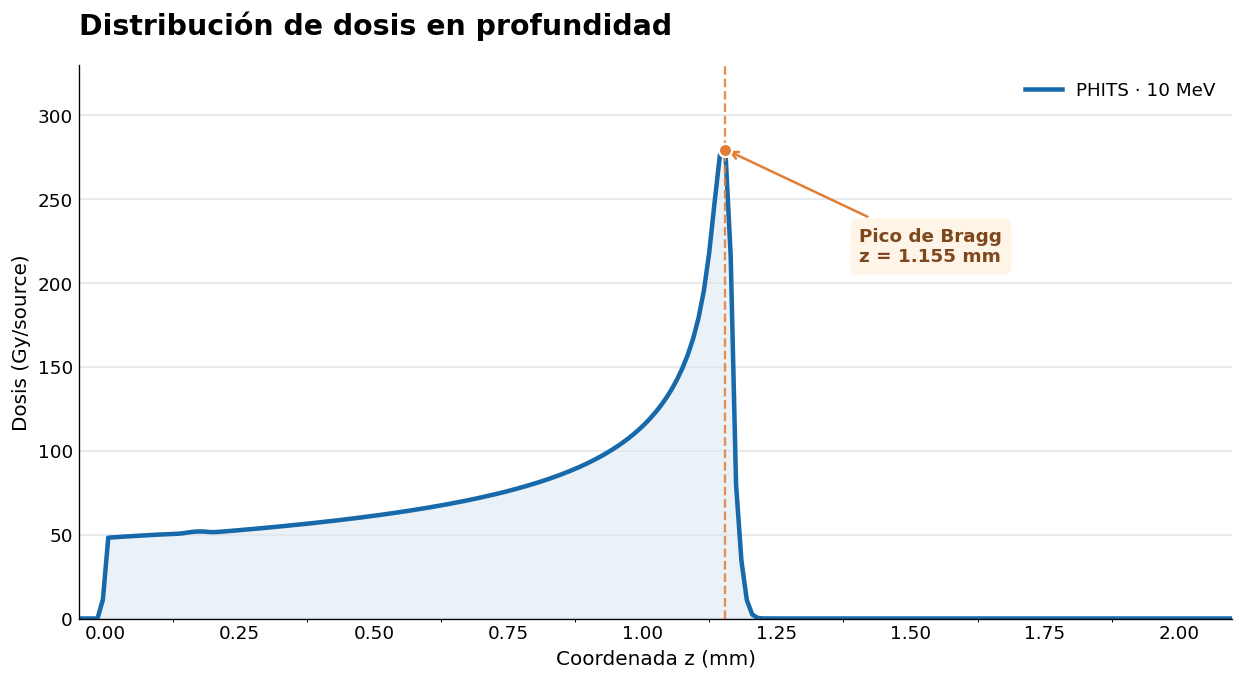

In [10]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 17,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})

fig, ax = plt.subplots(figsize=(10.5, 5.8), dpi=120)
azul, naranja = "#1769AA", "#E27D35"
ax.plot(df["z_mm"], df["dosis"], color=azul, lw=2.7, label="PHITS · 10 MeV")
ax.fill_between(df["z_mm"], df["dosis"], color=azul, alpha=0.09)
ax.scatter([z_pico_mm], [dosis_max], s=62, color=naranja, zorder=5, edgecolors="white", linewidths=1.3)
ax.axvline(z_pico_mm, color=naranja, ls="--", lw=1.4, alpha=0.85)
ax.annotate(f"Pico de Bragg\nz = {z_pico_mm:.3f} mm", xy=(z_pico_mm, dosis_max), xytext=(z_pico_mm + 0.25, dosis_max * 0.76), fontsize=11, color="#7F471C", fontweight="bold", arrowprops={"arrowstyle":"->", "lw":1.5, "color":naranja}, bbox={"boxstyle":"round,pad=0.5", "facecolor":"#FFF4E8", "edgecolor":"none"})
ax.set_title("Distribución de dosis en profundidad", loc="left", fontweight="bold", pad=18)
ax.set_xlabel("Coordenada z (mm)")
ax.set_ylabel("Dosis (Gy/source)")
ax.set_xlim(-0.05, 2.1)
ax.set_ylim(0, dosis_max * 1.18)
ax.grid(axis="y", color="#DFE5EA", lw=0.9)
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.tick_params(axis="both", length=0)
ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
plt.show()